# Machine Failure Early Warning

**Problem.** Unplanned machine failures stop production lines. We want to predict, from routine sensor readings, which machines are likely to fail so maintenance can be scheduled in advance.

**Intended user.** A maintenance planner who checks machine status at the start of each shift.

**Data.** [AI4I 2020 Predictive Maintenance Dataset (UCI 601)](https://archive.ics.uci.edu/dataset/601), 10,000 rows, public.

In [4]:
import os
import urllib.request
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.config import DATA_URL, MODEL_PATH, RANDOM_STATE, RAW_PATH, TARGET

sns.set_theme(style="whitegrid")

ModuleNotFoundError: No module named 'src'

## 1. Load data

In [ ]:
if not os.path.exists(RAW_PATH):
    os.makedirs("data/raw", exist_ok=True)
    zip_path, _ = urllib.request.urlretrieve(DATA_URL, "data/raw/ai4i.zip")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("data/raw")
    os.remove(zip_path)

df = pd.read_csv(RAW_PATH)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
print(df.shape)
df.info()

(10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 2. Data cleaning

In [ ]:
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate product IDs:", df["Product ID"].duplicated().sum())

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0
Duplicate product IDs: 0


`UDI` and `Product ID` are identifiers, not features.

`TWF`, `HDF`, `PWF`, `OSF`, `RNF` are the individual failure modes. They are only known **after** a failure happens, so keeping them would leak the target into the features. Drop them.

In [ ]:
df = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])

df = df.rename(columns={
    "Type": "type",
    "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k",
    "Rotational speed [rpm]": "rotational_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
    "Machine failure": "machine_failure",
})
df.head()

,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 3. Exploratory data analysis

machine_failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39%


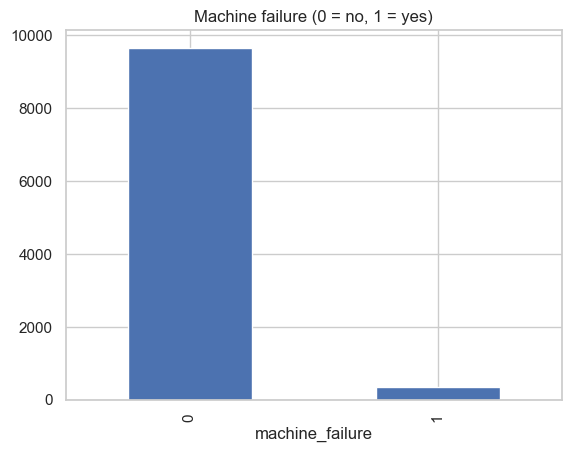

In [ ]:
print(df[TARGET].value_counts())
print(f"Failure rate: {df[TARGET].mean():.2%}")

df[TARGET].value_counts().plot(kind="bar")
plt.title("Machine failure (0 = no, 1 = yes)")
plt.show()

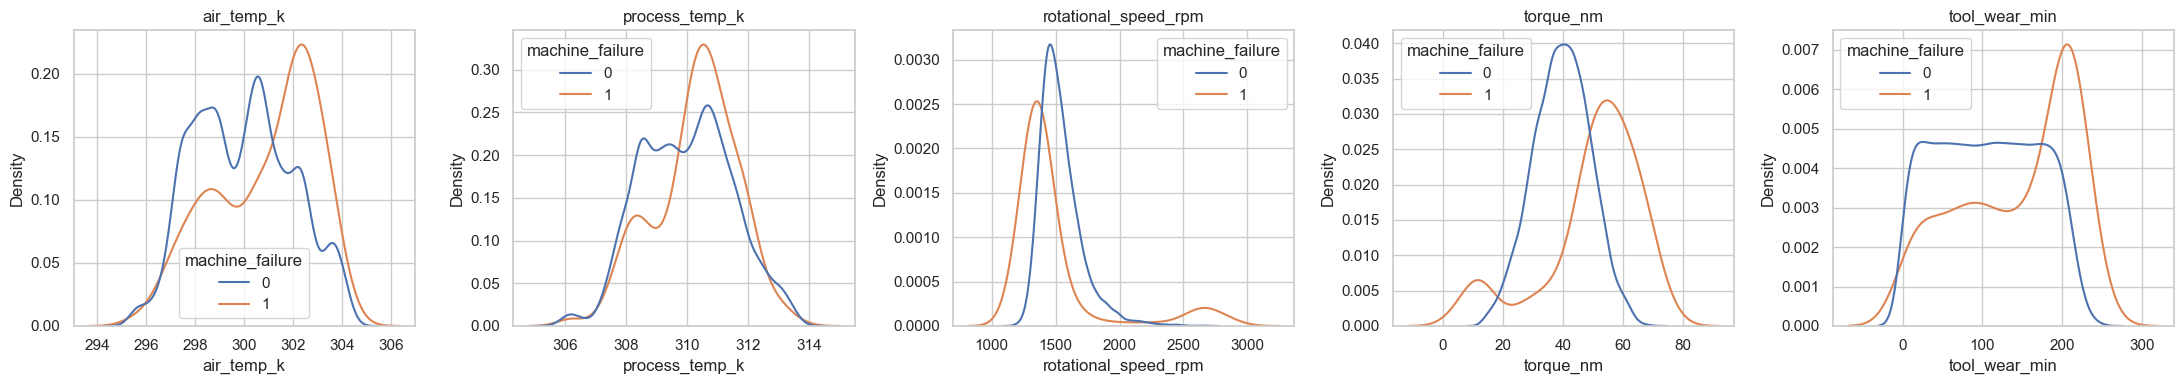

In [ ]:
num_cols = ["air_temp_k", "process_temp_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

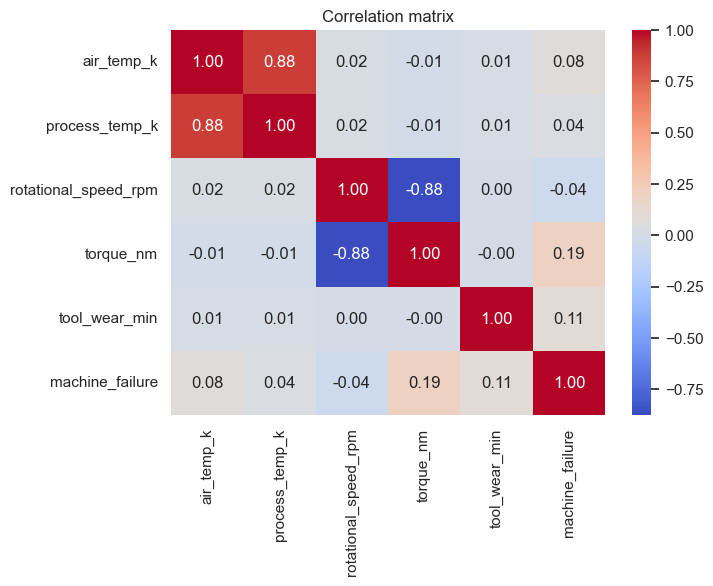

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [ ]:
df.groupby("type")[TARGET].agg(["mean", "count"]).rename(columns={"mean": "failure_rate"})

,failure_rate,count
type,,
H,0.020937,1003
L,0.039167,6000
M,0.027694,2997


Observations:
- Strong class imbalance (~3.4% failures) → accuracy is a misleading metric; use PR-AUC, recall and F1.
- Rotational speed and torque are strongly negatively correlated; failures concentrate at extreme torque and high tool wear.
- Air and process temperature are highly correlated; their difference may be more informative than either alone.

## 4. Feature engineering

In [ ]:
df["temp_diff_k"] = df["process_temp_k"] - df["air_temp_k"]
df["power_w"] = df["torque_nm"] * df["rotational_speed_rpm"] * 2 * np.pi / 60
df["strain"] = df["tool_wear_min"] * df["torque_nm"]

df = pd.get_dummies(df, columns=["type"], prefix="type", dtype=int)
df.head()

,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,temp_diff_k,power_w,strain,type_H,type_L,type_M
0,298.1,308.6,1551,42.8,0,0,10.5,6951.590560,0.0,0,0,1
1,298.2,308.7,1408,46.3,3,0,10.5,6826.722724,138.9,0,1,0
2,298.1,308.5,1498,49.4,5,0,10.4,7749.387543,247.0,0,1,0
3,298.2,308.6,1433,39.5,7,0,10.4,5927.504659,276.5,0,1,0
4,298.2,308.7,1408,40.0,9,0,10.5,5897.816608,360.0,0,1,0


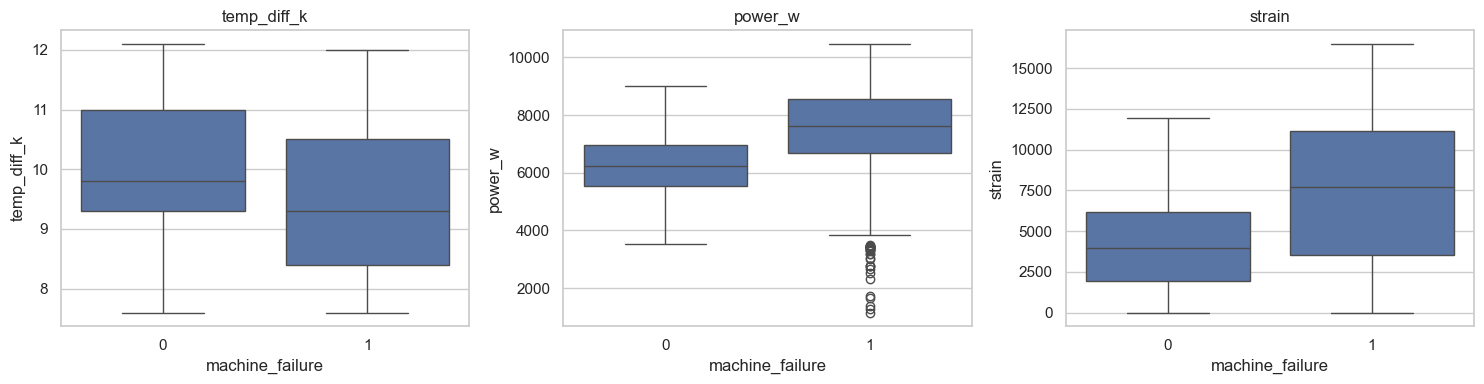

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["temp_diff_k", "power_w", "strain"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Train / test split

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print(f"Train failure rate: {y_train.mean():.2%} | Test failure rate: {y_test.mean():.2%}")

(8000, 11) (2000, 11)
Train failure rate: 3.39% | Test failure rate: 3.40%


## 6. Baseline models

### 6.1 Logistic regression

In [ ]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
)
logreg.fit(X_train, y_train)

y_pred_lr = logreg.predict(X_test)
y_proba_lr = logreg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_lr))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_lr):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba_lr):.3f}")

              precision    recall  f1-score   support

           0      0.995     0.859     0.922      1932
           1      0.180     0.882     0.299        68

    accuracy                          0.860      2000
   macro avg      0.588     0.871     0.611      2000
weighted avg      0.967     0.860     0.901      2000

Confusion matrix:
 [[1659  273]
 [   8   60]]
ROC-AUC: 0.938
PR-AUC:  0.430


### 6.2 Random forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf, digits=3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_rf))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba_rf):.3f}")

              precision    recall  f1-score   support

           0      0.994     0.998     0.996      1932
           1      0.949     0.824     0.882        68

    accuracy                          0.993      2000
   macro avg      0.971     0.911     0.939      2000
weighted avg      0.992     0.993     0.992      2000

Confusion matrix:
 [[1929    3]
 [  12   56]]
ROC-AUC: 0.969
PR-AUC:  0.869


## 7. Compare models

In [ ]:
results = pd.DataFrame({
    "model": ["Logistic regression", "Random forest"],
    "f1": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)],
    "roc_auc": [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_rf)],
    "pr_auc": [average_precision_score(y_test, y_proba_lr), average_precision_score(y_test, y_proba_rf)],
})
results.round(3)

,model,f1,roc_auc,pr_auc
0,Logistic regression,0.299,0.938,0.430
1,Random forest,0.882,0.969,0.869


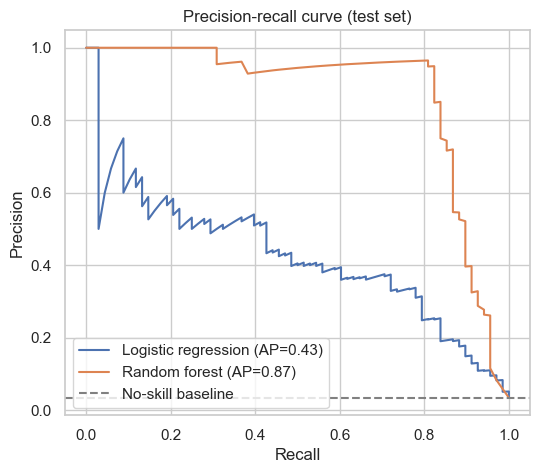

In [ ]:
plt.figure(figsize=(6, 5))
for name, proba in [("Logistic regression", y_proba_lr), ("Random forest", y_proba_rf)]:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, proba):.2f})")
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="No-skill baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curve (test set)")
plt.legend()
plt.show()

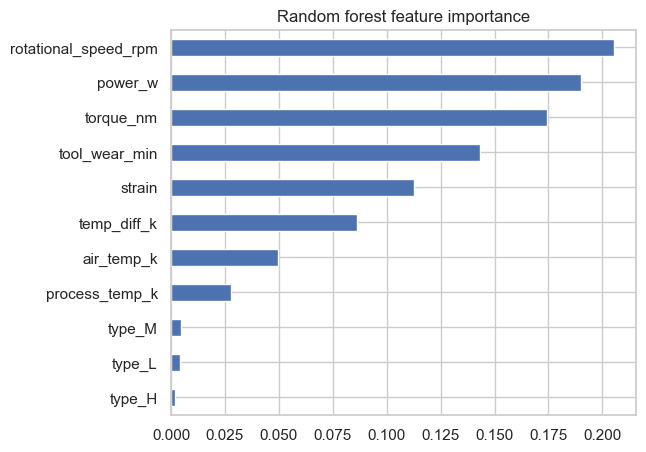

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(6, 5))
plt.title("Random forest feature importance")
plt.show()

## 8. Save the model

In [ ]:
os.makedirs("models", exist_ok=True)
joblib.dump(rf, MODEL_PATH)
print("Saved model to", MODEL_PATH)

Saved model to models/random_forest.joblib


## 9. Predict for a new machine reading (microproduct prototype)

In [ ]:
def predict_failure_risk(reading):
    model = joblib.load(MODEL_PATH)
    row = pd.DataFrame([reading])
    row["temp_diff_k"] = row["process_temp_k"] - row["air_temp_k"]
    row["power_w"] = row["torque_nm"] * row["rotational_speed_rpm"] * 2 * np.pi / 60
    row["strain"] = row["tool_wear_min"] * row["torque_nm"]
    row = pd.get_dummies(row, columns=["type"], prefix="type", dtype=int)
    row = row.reindex(columns=X.columns, fill_value=0)
    return model.predict_proba(row)[0, 1]


new_reading = {
    "type": "L",
    "air_temp_k": 302.5,
    "process_temp_k": 310.9,
    "rotational_speed_rpm": 1320,
    "torque_nm": 62.0,
    "tool_wear_min": 215,
}
risk = predict_failure_risk(new_reading)
print(f"Failure risk: {risk:.1%}")

Failure risk: 97.3%
